# Baseline: DR grading with EfficientNetV2-S
Two-phase transfer learning on the MMRDR CFP dataset (TensorFlow/Keras).

## 0. Setup
Imports, configuration (`CFG`), seeds and GPU settings.

In [1]:
import io
import json
import math
import os
import platform
import random
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")              # hide TensorFlow start-up noise
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import ndimage, stats
from scipy.special import log_softmax, softmax
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import sklearn
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report, cohen_kappa_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
import tensorflow as tf
import keras
from keras import layers
from PIL import Image

ON_KAGGLE = Path("/kaggle/input").exists()
SMOKE = os.environ.get("DRXAI_SMOKE", "0") == "1"

CFG = dict(
    seed=42,
    img_size=512,
    val_frac=0.125,                # 7:1 train:val, as in the MMRDR evaluation code
    batch_size=16,
    epochs_phase1=10,
    epochs_phase2=25,
    lr_phase1=1e-3,                # head-only training: normal learning rate
    lr_phase2=1e-4,
    weight_decay=1e-4,
    head_units=256,                # hidden layer of the custom head
    head_dropout=0.3,
    class_weight_power=0.5,        # sqrt inverse-frequency class weights
    patience=6,
    mixed_precision=True,
    n_bootstrap=1000,
    referral_rate=0.20,            # confidence threshold set on VAL to refer 20 %
    dup_hamming=2,
)
if SMOKE:
    CFG.update(img_size=128, batch_size=8, epochs_phase1=2, epochs_phase2=2, n_bootstrap=50)

MODEL_NAME = "effnetv2s_baseline_tf"
GRADES = ["No DR", "Mild NPDR", "Moderate NPDR", "Severe NPDR", "PDR"]
LESIONS = ["MA", "HE", "IH", "VB/IRMA", "NV", "VH", "RD"]
K = len(GRADES)
SIZE = CFG["img_size"]


def seed_everything(seed):
    """Fix Python, NumPy and TensorFlow seeds (GPU kernels may still differ in the last decimals)."""
    random.seed(seed); np.random.seed(seed); keras.utils.set_random_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


gpus = tf.config.list_physical_devices("GPU")
if gpus:
    tf.config.set_visible_devices(gpus[0], "GPU")
    tf.config.experimental.set_memory_growth(gpus[0], True)
MIXED = CFG["mixed_precision"] and (bool(gpus) or os.environ.get("DRXAI_FORCE_MIXED") == "1")   # env var: test on CPU
keras.mixed_precision.set_global_policy("mixed_float16" if MIXED else "float32")
seed_everything(CFG["seed"])
AUTOTUNE = tf.data.AUTOTUNE

ROOT = Path("/kaggle/working") if ON_KAGGLE else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
OUT_DIR = Path(os.environ.get("DRXAI_OUT", ROOT / "outputs_effnetv2s_baseline_tf"))
if SMOKE:
    OUT_DIR = OUT_DIR / "smoke"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(OUT_DIR / "config.json", "w"), indent=2)


def savefig(name):
    plt.savefig(OUT_DIR / "figures" / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()


print(f"GPU: {gpus[0].name if gpus else 'none (CPU)'} | mixed precision={MIXED} | smoke={SMOKE} kaggle={ON_KAGGLE} out={OUT_DIR}")
print("python", platform.python_version(), "| tensorflow", tf.__version__, "| keras", keras.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| scipy", scipy.__version__)

GPU: /physical_device:GPU:0 | mixed precision=True | smoke=False kaggle=True out=/kaggle/working/outputs_effnetv2s_baseline_tf
python 3.13.15 | tensorflow 2.20.0 | keras 3.13.2 | numpy 2.1.3 | pandas 2.3.3 | sklearn 1.6.1 | scipy 1.16.3


## 1. Load data
Locate the preprocessed MMRDR CFP dataset (512×512) and read the labels.

In [2]:
def find_data_dir():
    cands = [os.environ.get("DRXAI_DATA", ""), str(ROOT / "data" / "cfp512")]
    if ON_KAGGLE:
        cands += [str(p.parent) for p in Path("/kaggle/input").rglob("FP.csv")]
    for c in cands:
        if c and (Path(c) / "FP.csv").exists() and (Path(c) / "img").is_dir():
            return Path(c)
    raise FileNotFoundError("Attach the Kaggle dataset 'mmrdr-cfp512' (or set DRXAI_DATA).")


DATA_DIR = find_data_dir()
IMG_DIR = DATA_DIR / "img"
df = pd.read_csv(DATA_DIR / "FP.csv")
df["file"] = df["image"].str.split("/").str[-1]
df["split"] = np.where(df["file"].str.startswith("ts"), "test", "train")
L = np.array([json.loads(s) for s in df["lesion"]], dtype=np.int64)
for i, name in enumerate(LESIONS):
    df[name] = L[:, i]

print(f"DATA_DIR = {DATA_DIR} | {len(df)} labelled images")

DATA_DIR = /kaggle/input/datasets/mariajabeen01/mmrdr-cfp512/cfp512 | 11118 labelled images


## 2. Data inspection
### 2.1 Grade distribution
Class counts per split; the data are heavily imbalanced (≈59 % No DR).

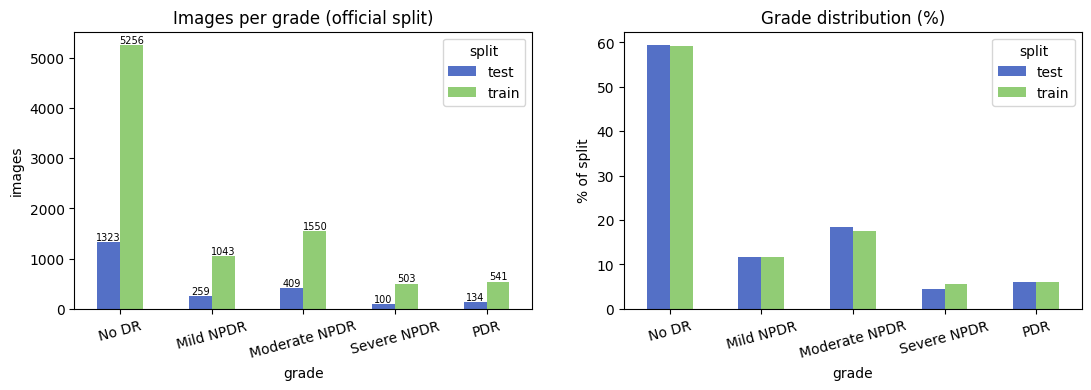

Imbalance ratio (largest/smallest train class): 10.4x | majority-class accuracy on test: 0.595 | laterality L/R: 5607/5511


split,test,train,train %,test %
grade,,,,
No DR,1323,5256,59.1,59.5
Mild NPDR,259,1043,11.7,11.6
Moderate NPDR,409,1550,17.4,18.4
Severe NPDR,100,503,5.7,4.5
PDR,134,541,6.1,6.0


In [3]:
counts = pd.crosstab(df["grade"], df["split"]).rename(index=dict(enumerate(GRADES)))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
counts.plot.bar(ax=axs[0], rot=15, color=["#5470c6", "#91cc75"])
for c in axs[0].containers:
    axs[0].bar_label(c, fontsize=7)
axs[0].set_title("Images per grade (official split)"); axs[0].set_ylabel("images")
(counts / counts.sum() * 100).plot.bar(ax=axs[1], rot=15, color=["#5470c6", "#91cc75"])
axs[1].set_title("Grade distribution (%)"); axs[1].set_ylabel("% of split")
savefig("01_grade_distribution")
imb = counts["train"].max() / counts["train"].min()
print(f"Imbalance ratio (largest/smallest train class): {imb:.1f}x | majority-class accuracy on test: "
      f"{(df[df.split == 'test'].grade == 0).mean():.3f} | laterality L/R: {(df.lr == 0).sum()}/{(df.lr == 1).sum()}")
display(counts.assign(**{"train %": (100 * counts.train / counts.train.sum()).round(1),
                         "test %": (100 * counts.test / counts.test.sum()).round(1)}))

### 2.2 Lesions vs grade
Lesion prevalence per grade and grading-rule checks on the labels.

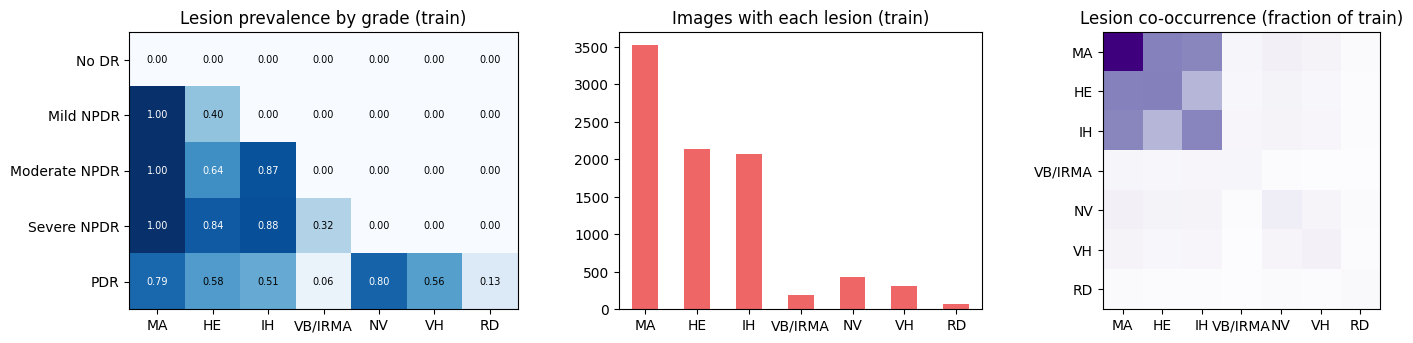

Lowest grade at which each lesion occurs: {'MA': 1, 'HE': 1, 'IH': 2, 'VB/IRMA': 3, 'NV': 4, 'VH': 4, 'RD': 4}
Rule violations in the ground truth (all images): {'under_graded_vs_lesions': 0, 'dr_without_lesions': 0, 'pdr_without_pdr_lesion': 0, 'npdr_without_ma': 0, 'no_dr_with_lesions': 0}
Mild NPDR with hard exudates: 537 / 1302 (the paper defines Mild NPDR as microaneurysms only)
Severe NPDR with VB/IRMA: 197 / 603 (most severe cases are defined by lesion extent, which presence flags cannot express)


In [4]:
tr_lab = df[df.split == "train"]
prev = tr_lab.groupby("grade")[LESIONS].mean().rename(index=dict(enumerate(GRADES)))
co = tr_lab[LESIONS].T.dot(tr_lab[LESIONS]) / len(tr_lab)
fig, axs = plt.subplots(1, 3, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
im = axs[0].imshow(prev.values, cmap="Blues", vmin=0, vmax=1)
axs[0].set_xticks(range(7), LESIONS); axs[0].set_yticks(range(K), prev.index)
for (r, c), v in np.ndenumerate(prev.values):
    axs[0].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > .6 else "black")
axs[0].set_title("Lesion prevalence by grade (train)")
tr_lab[LESIONS].sum().plot.bar(ax=axs[1], rot=0, color="#ee6666"); axs[1].set_title("Images with each lesion (train)")
axs[2].imshow(co.values, cmap="Purples"); axs[2].set_xticks(range(7), LESIONS); axs[2].set_yticks(range(7), LESIONS)
axs[2].set_title("Lesion co-occurrence (fraction of train)")
savefig("02_lesions")

MIN_GRADE = {l: int(tr_lab.loc[tr_lab[l] == 1, "grade"].min()) for l in LESIONS}
PDR_LESIONS = [l for l in LESIONS if MIN_GRADE[l] == 4]


def rule_violations(grade, present, absent=None):
    """Grade/lesion combinations that contradict the grading protocol (ICDR-style 4-2-1 rule)."""
    present = present.astype(bool)
    absent = ~present if absent is None else absent.astype(bool)
    implied = np.where(present, np.array([MIN_GRADE[l] for l in LESIONS])[None, :], 0).max(1)
    pdr = [LESIONS.index(l) for l in PDR_LESIONS]
    return pd.DataFrame({
        "under_graded_vs_lesions": grade < implied,
        "dr_without_lesions": (grade >= 1) & absent.all(1),
        "pdr_without_pdr_lesion": (grade == 4) & absent[:, pdr].all(1),
        "npdr_without_ma": np.isin(grade, [1, 2, 3]) & absent[:, LESIONS.index("MA")],
        "no_dr_with_lesions": (grade == 0) & present.any(1),
    })


print("Lowest grade at which each lesion occurs:", MIN_GRADE)
print("Rule violations in the ground truth (all images):", rule_violations(df.grade.values, df[LESIONS].values).sum().to_dict())
print(f"Mild NPDR with hard exudates: {((df.grade == 1) & (df.HE == 1)).sum()} / {(df.grade == 1).sum()} "
      f"(the paper defines Mild NPDR as microaneurysms only)")
print(f"Severe NPDR with VB/IRMA: {((df.grade == 3) & (df['VB/IRMA'] == 1)).sum()} / {(df.grade == 3).sum()} "
      f"(most severe cases are defined by lesion extent, which presence flags cannot express)")

### 2.3 Image quality
Brightness, contrast and sharpness per image, with the worst examples.

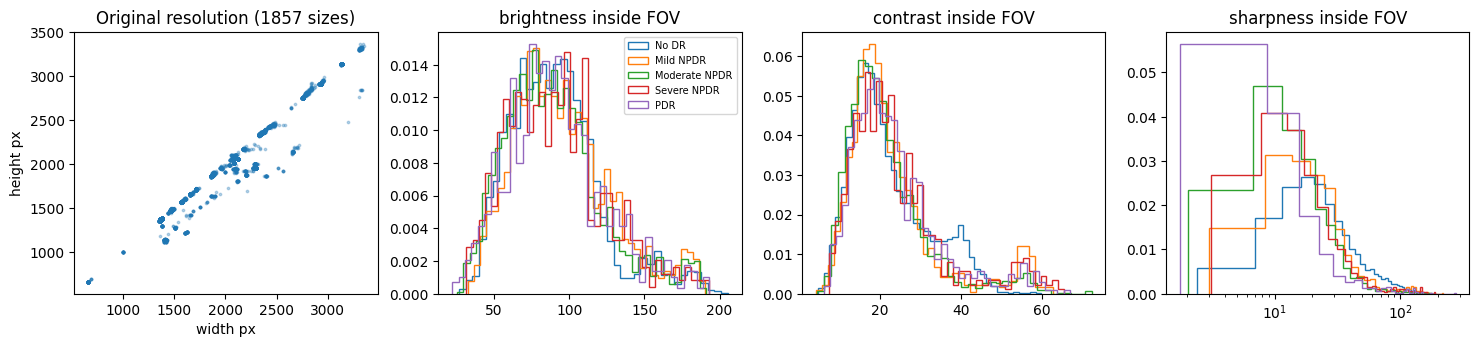

Lowest-5% sharpness images: 556; very dark (brightness < 40): 161; very bright (> 200): 3


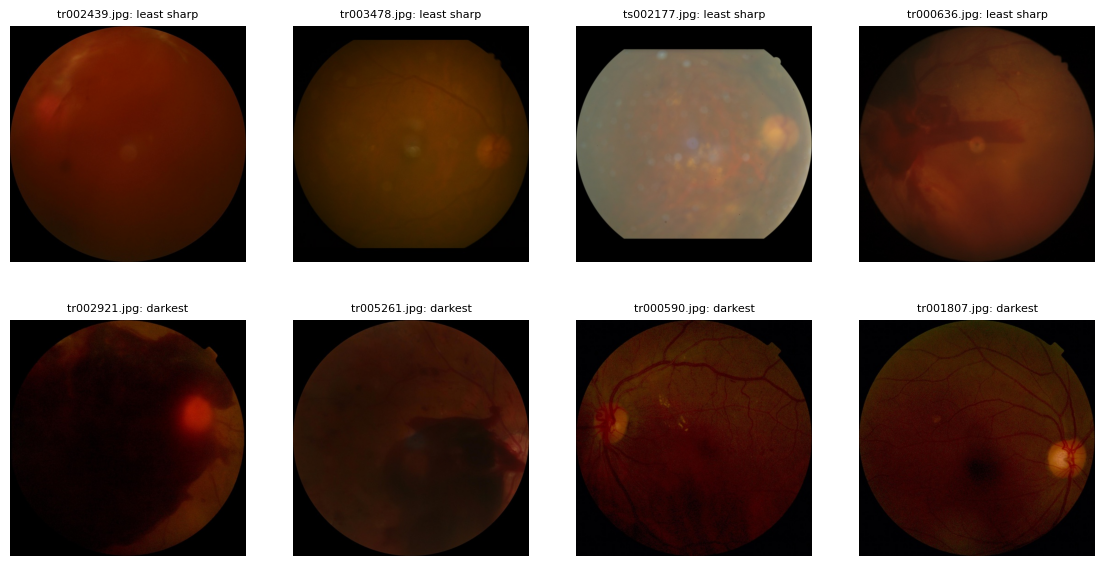

In [5]:
def image_stats(path):
    a = np.asarray(Image.open(path).convert("RGB").resize((256, 256), Image.BILINEAR), dtype=np.float32)
    fov = ndimage.binary_erosion(a.max(2) > 15, iterations=6)
    g = a.mean(2); lap = ndimage.laplace(g)
    d = np.asarray(Image.open(path).convert("L").resize((17, 16), Image.BILINEAR), dtype=np.int16)
    ok = fov.any()
    return dict(brightness=g[fov].mean() if ok else 0., contrast=g[fov].std() if ok else 0.,
                sharpness=lap[fov].var() if ok else 0., red=a[..., 0][fov].mean() if ok else 0.,
                dhash=np.packbits((d[:, 1:] > d[:, :-1]).flatten()).tobytes().hex())


stats_path = OUT_DIR / "image_stats.csv"
if stats_path.exists():
    st = pd.read_csv(stats_path)
else:
    with ThreadPoolExecutor(max_workers=os.cpu_count() or 4) as ex:
        st = pd.DataFrame(list(ex.map(image_stats, [IMG_DIR / f for f in df["file"]]))).assign(file=df["file"].values)
    st.to_csv(stats_path, index=False)
df = df.merge(st, on="file", how="left")
meta = pd.read_csv(DATA_DIR / "prep_meta.csv").drop_duplicates("image")
df = df.merge(meta[["image", "orig_w", "orig_h"]], on="image", how="left")

fig, axs = plt.subplots(1, 4, figsize=(18, 3.4))
axs[0].scatter(df.orig_w, df.orig_h, s=3, alpha=.3); axs[0].set_title(f"Original resolution ({df[['orig_w', 'orig_h']].drop_duplicates().shape[0]} sizes)")
axs[0].set_xlabel("width px"); axs[0].set_ylabel("height px")
for ax, col in zip(axs[1:], ["brightness", "contrast", "sharpness"]):
    for g in range(K):
        ax.hist(df.loc[df.grade == g, col], bins=40, histtype="step", density=True, label=GRADES[g])
    ax.set_title(f"{col} inside FOV")
axs[3].set_xscale("log"); axs[1].legend(fontsize=7)
savefig("03_quality_proxies")
q_lo = df.sharpness.quantile(0.05)
print(f"Lowest-5% sharpness images: {(df.sharpness < q_lo).sum()}; very dark (brightness < 40): {(df.brightness < 40).sum()}; "
      f"very bright (> 200): {(df.brightness > 200).sum()}")

fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for ax, f in zip(axs[0], df.sort_values("sharpness").file.head(4)):
    ax.imshow(Image.open(IMG_DIR / f)); ax.axis("off"); ax.set_title(f"{f}: least sharp", fontsize=8)
for ax, f in zip(axs[1], df.sort_values("brightness").file.head(4)):
    ax.imshow(Image.open(IMG_DIR / f)); ax.axis("off"); ax.set_title(f"{f}: darkest", fontsize=8)
savefig("04_low_quality_examples")

### 2.4 Duplicates
Find near-identical photographs with a difference hash (dHash).

Exact-duplicate pairs: 153 | groups: 133 (275 images) | groups spanning train+test: 44 -> 45 test images leak | groups with CONFLICTING grades: 3


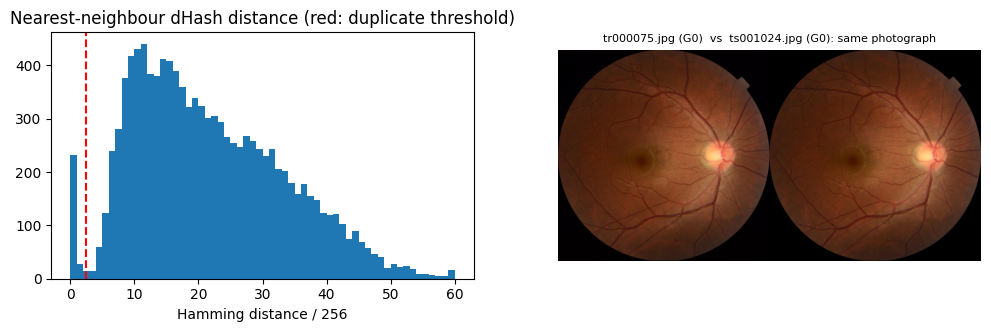

In [6]:
def hamming_groups(hex_list, thr, chunk=128):
    """Connected components of 'Hamming distance <= thr' over all images, plus each image's nearest neighbour."""
    H = np.stack([np.frombuffer(bytes.fromhex(h), np.uint8) for h in hex_list])
    pop = np.unpackbits(np.arange(256, dtype=np.uint8)[:, None], axis=1).sum(1).astype(np.uint8)
    rows, cols, nn_d = [], [], np.empty(len(H), int)
    for s in range(0, len(H), chunk):
        d = pop[H[s:s + chunk, None, :] ^ H[None, :, :]].sum(2, dtype=np.int32)
        d[np.arange(d.shape[0]), np.arange(s, s + d.shape[0])] = 999
        nn_d[s:s + chunk] = d.min(1)
        r, c = np.nonzero(d <= thr); keep = (r + s) < c
        rows.append(r[keep] + s); cols.append(c[keep])
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    groups = connected_components(coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(H),) * 2), directed=False)[1]
    return groups, nn_d, list(zip(rows, cols))


df["dup_group"], df["nn_hamming"], dup_pairs = hamming_groups(df.dhash.values, CFG["dup_hamming"])
g = df.groupby("dup_group").agg(n=("file", "size"), grades=("grade", "nunique"), splits=("split", lambda x: "+".join(sorted(set(x)))))
multi = g[g.n > 1]
te_dup_groups = set(multi[multi.splits == "test+train"].index)
df["test_dup_of_train"] = (df.split == "test") & df.dup_group.isin(te_dup_groups)
print(f"Exact-duplicate pairs: {len(dup_pairs)} | groups: {len(multi)} ({multi.n.sum()} images) | "
      f"groups spanning train+test: {len(te_dup_groups)} -> {df.test_dup_of_train.sum()} test images leak | "
      f"groups with CONFLICTING grades: {(multi.grades > 1).sum()}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
axs[0].hist(df.nn_hamming.clip(upper=60), bins=60); axs[0].axvline(CFG["dup_hamming"] + .5, color="r", ls="--")
axs[0].set_title("Nearest-neighbour dHash distance (red: duplicate threshold)"); axs[0].set_xlabel("Hamming distance / 256")
for (i, j), ax in zip(dup_pairs[:1], [axs[1]]):
    ax.imshow(np.concatenate([np.asarray(Image.open(IMG_DIR / df.file[i])), np.asarray(Image.open(IMG_DIR / df.file[j]))], 1))
    ax.axis("off"); ax.set_title(f"{df.file[i]} (G{df.grade[i]})  vs  {df.file[j]} (G{df.grade[j]}): same photograph", fontsize=8)
savefig("05_duplicates")

### 2.5 Examples
Sample training images per grade with their annotated lesions.

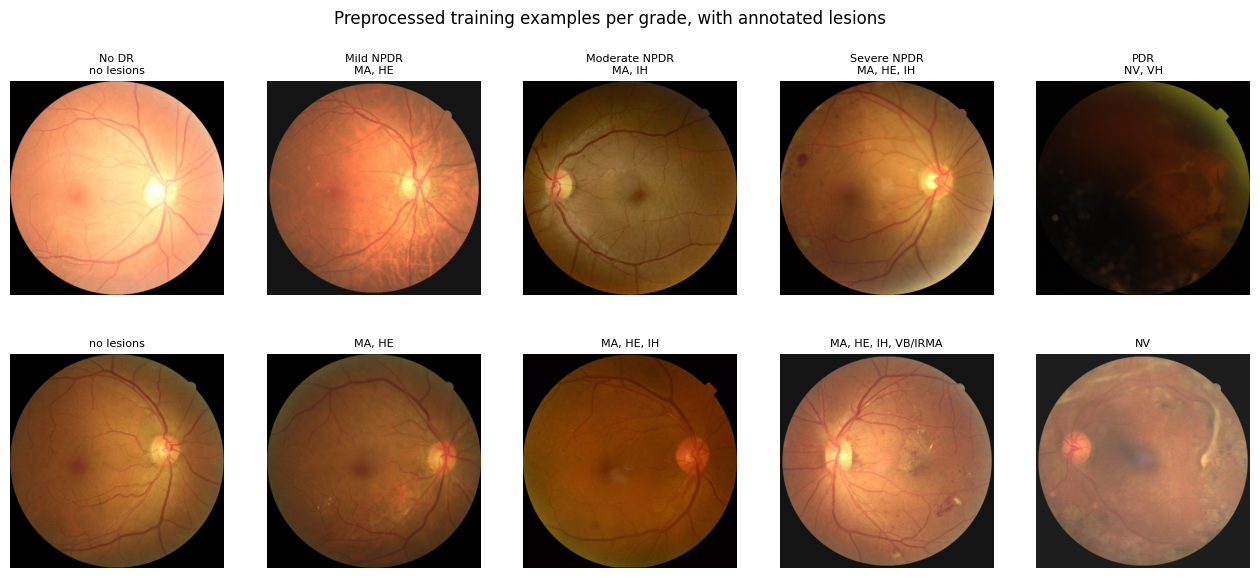

In [7]:
fig, axs = plt.subplots(2, K, figsize=(16, 6.5))
r = np.random.default_rng(CFG["seed"])
for g_ in range(K):
    fs = df[(df.split == "train") & (df.grade == g_)].file.values
    for row in range(2):
        f = r.choice(fs)
        axs[row, g_].imshow(Image.open(IMG_DIR / f)); axs[row, g_].axis("off")
        les = ", ".join(l for l in LESIONS if df.loc[df.file == f, l].item() == 1) or "no lesions"
        axs[row, g_].set_title((GRADES[g_] + "\n" if row == 0 else "") + les, fontsize=8)
plt.suptitle("Preprocessed training examples per grade, with annotated lesions")
savefig("06_examples_per_grade")

## 3. Augmentation
On-the-fly crop, flips, rotation and colour jitter (no hue shift); images stay in [0, 255].

I0000 00:00:1792946835.763893      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


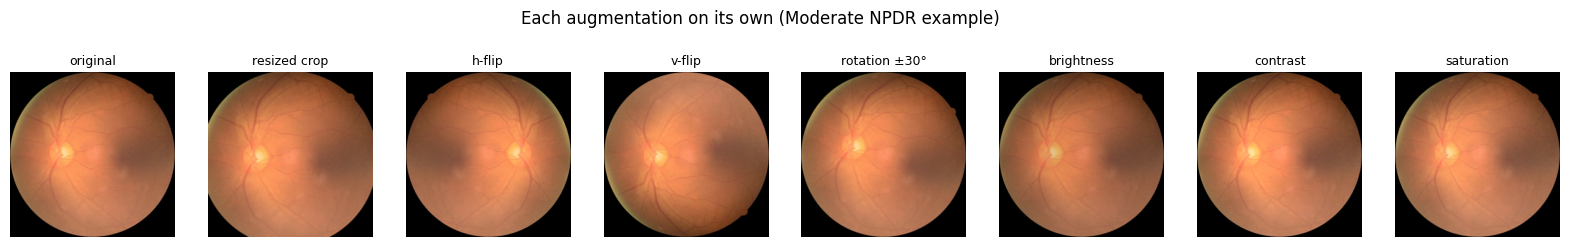

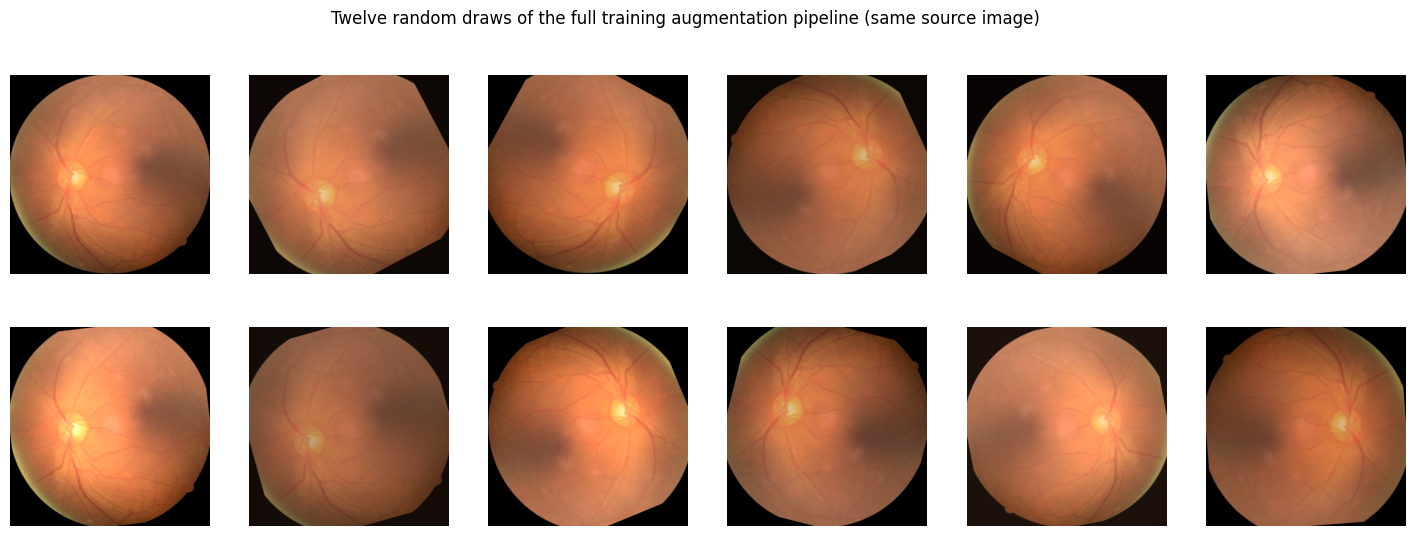

In [8]:
def preprocess(img):
    """Keras EfficientNetV2 normalises inside the model (rescaling layer): pass raw RGB 0-255 through."""
    return img


def to_display(x):
    """Image in [0, 255] -> [0, 1] for plotting."""
    return np.clip(np.asarray(x, dtype=np.float32) / 255.0, 0, 1)


def load_image(path):
    """Read a preprocessed 512-px JPEG as float32 RGB in [0, 255] (resized only in the smoke test)."""
    img = tf.cast(tf.io.decode_jpeg(tf.io.read_file(path), channels=3), tf.float32)
    return tf.image.resize(img, (SIZE, SIZE)) if SIZE != 512 else tf.ensure_shape(img, (512, 512, 3))


def random_resized_crop(img, scale=(0.85, 1.0), ratio=(0.95, 1.05)):
    h, w = tf.cast(tf.shape(img)[0], tf.float32), tf.cast(tf.shape(img)[1], tf.float32)
    area = h * w * tf.random.uniform([], *scale)
    r = tf.exp(tf.random.uniform([], math.log(ratio[0]), math.log(ratio[1])))
    ch = tf.cast(tf.minimum(tf.sqrt(area / r), h), tf.int32)
    cw = tf.cast(tf.minimum(tf.sqrt(area * r), w), tf.int32)
    return tf.image.resize(tf.image.random_crop(img, tf.stack([ch, cw, 3])), (SIZE, SIZE))


rotate = layers.RandomRotation(30 / 360, fill_mode="constant", fill_value=0.0, seed=CFG["seed"], dtype="float32")


def augment(img):
    """Training augmentation on a float32 RGB image in [0, 255]."""
    img = random_resized_crop(img)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.cast(rotate(img, training=True), tf.float32)
    x = img / 255.0
    x = x * tf.random.uniform([], 0.8, 1.2)                        # brightness ±20 %
    x = tf.image.random_contrast(x, 0.8, 1.2)                      # contrast ±20 %
    x = tf.image.random_saturation(tf.clip_by_value(x, 0, 1), 0.9, 1.1)   # saturation ±10 %, no hue change
    return tf.clip_by_value(x, 0.0, 1.0) * 255.0


demo_path = str(IMG_DIR / df[(df.split == "train") & (df.grade == 2)].file.iloc[0])
demo = load_image(demo_path)
single = {"original": lambda im: im,
          "resized crop": random_resized_crop,
          "h-flip": tf.image.flip_left_right, "v-flip": tf.image.flip_up_down,
          "rotation ±30°": lambda im: tf.cast(rotate(im, training=True), tf.float32),
          "brightness": lambda im: tf.clip_by_value(im * tf.random.uniform([], 0.8, 1.2), 0, 255),
          "contrast": lambda im: tf.clip_by_value(tf.image.random_contrast(im, 0.8, 1.2), 0, 255),
          "saturation": lambda im: tf.image.random_saturation(im / 255.0, 0.9, 1.1) * 255.0}
tf.random.set_seed(1)
fig, axs = plt.subplots(1, len(single), figsize=(20, 3))
for ax, (nm, t) in zip(axs, single.items()):
    ax.imshow(np.clip(np.asarray(t(demo), dtype=np.float32) / 255.0, 0, 1)); ax.axis("off"); ax.set_title(nm, fontsize=9)
plt.suptitle("Each augmentation on its own (Moderate NPDR example)")
savefig("07_augmentation_individual")
fig, axs = plt.subplots(2, 6, figsize=(18, 6))
for ax in axs.flat:
    ax.imshow(to_display(preprocess(augment(demo)))); ax.axis("off")
plt.suptitle("Twelve random draws of the full training augmentation pipeline (same source image)")
savefig("08_augmentation_pipeline")

## 4. Data split
Stratified train/validation split grouped by duplicate; official test set held out.

,train,val,test
No DR,4582,674,1323
Mild NPDR,911,132,259
Moderate NPDR,1368,182,409
Severe NPDR,440,63,100
PDR,482,59,134


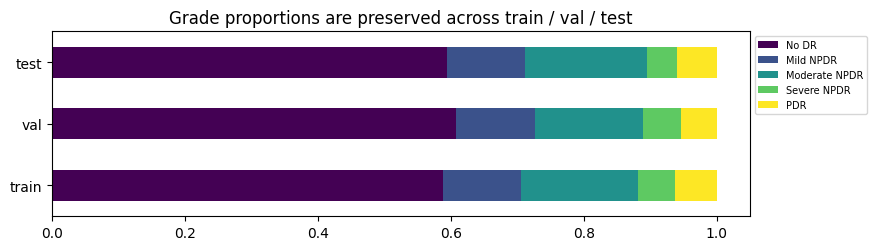

In [9]:
dev = df[df.split == "train"].reset_index(drop=True)
sgkf = StratifiedGroupKFold(n_splits=round(1 / CFG["val_frac"]), shuffle=True, random_state=CFG["seed"])
tr_i, va_i = next(sgkf.split(dev, dev["grade"], groups=dev["dup_group"]))
tr_df, va_df, te_df = dev.iloc[tr_i], dev.iloc[va_i], df[df.split == "test"]
assert not set(tr_df.dup_group) & set(va_df.dup_group)
if SMOKE:
    take = lambda d, n: pd.concat([x.sample(min(len(x), n), random_state=0) for _, x in d.groupby("grade")])
    tr_df, va_df, te_df = take(tr_df, 24), take(va_df, 12), take(te_df, 16)
tr_df, va_df, te_df = (d.reset_index(drop=True) for d in (tr_df, va_df, te_df))
pd.concat([tr_df.assign(subset="train"), va_df.assign(subset="val"), te_df.assign(subset="test")])[
    ["file", "grade", "subset"]].to_csv(OUT_DIR / "split.csv", index=False)
split_tbl = pd.DataFrame({n: d.grade.value_counts().sort_index() for n, d in [("train", tr_df), ("val", va_df), ("test", te_df)]})
split_tbl.index = GRADES
display(split_tbl)
(split_tbl / split_tbl.sum()).T.plot.barh(stacked=True, figsize=(9, 2.4), colormap="viridis")
plt.title("Grade proportions are preserved across train / val / test"); plt.legend(fontsize=7, bbox_to_anchor=(1, 1))
savefig("09_split")

### 4.1 Datasets and class weights
`tf.data` pipelines and sqrt inverse-frequency class weights.

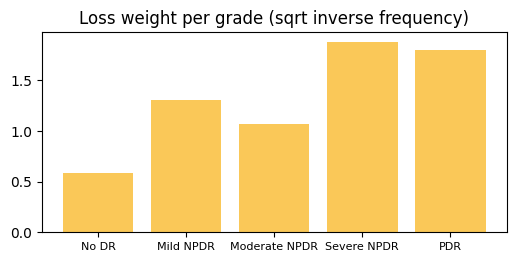

In [10]:
freq = np.bincount(tr_df.grade, minlength=K) / len(tr_df)
CLASS_W = ((1 / (K * np.maximum(freq, 1e-6))) ** CFG["class_weight_power"]).astype(np.float32)


def make_ds(frame, train, perturb=None, batch_size=None):
    """tf.data pipeline yielding (preprocessed image, grade, class weight). `perturb` degrades images (Sec. 9)."""
    paths = [str(IMG_DIR / f) for f in frame["file"]]
    y = frame["grade"].values.astype(np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, y, CLASS_W[y]))
    if train:
        ds = ds.shuffle(len(paths), seed=CFG["seed"], reshuffle_each_iteration=True)

    def _map(p, label, w):
        img = load_image(p)
        if train:
            img = augment(img)
        if perturb is not None:
            img = perturb(img)
        return preprocess(img), label, w

    return (ds.map(_map, num_parallel_calls=AUTOTUNE)
              .batch(batch_size or CFG["batch_size"], drop_remainder=train).prefetch(AUTOTUNE))


fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(GRADES, CLASS_W, color="#fac858"); ax.set_title("Loss weight per grade (sqrt inverse frequency)")
ax.tick_params(axis="x", labelsize=8); savefig("10_class_weights")

## 5. Model
EfficientNetV2-S backbone with a custom grade head (5 classes).

In [11]:
def build_model(weights="imagenet"):
    """EfficientNetV2-S backbone + custom head (outputs float32 logits). Input: raw RGB in [0, 255]."""
    inp = keras.Input((SIZE, SIZE, 3), name="image")
    base = keras.applications.EfficientNetV2S(include_top=False, weights=weights, input_tensor=inp,
                                              include_preprocessing=True)
    x = layers.GlobalAveragePooling2D(name="head_gap")(base.output)
    x = layers.BatchNormalization(name="head_bn1")(x)
    x = layers.Dropout(CFG["head_dropout"], name="head_drop1")(x)
    x = layers.Dense(CFG["head_units"], activation="relu", name="head_dense")(x)
    x = layers.BatchNormalization(name="head_bn2")(x)
    x = layers.Dropout(CFG["head_dropout"], name="head_drop2")(x)
    out = layers.Dense(K, dtype="float32", name="head_out")(x)
    return keras.Model(inp, out, name="effnetv2s_dr")


model = build_model()
HEAD = [l for l in model.layers if l.name.startswith("head_")]
BACKBONE = [l for l in model.layers if not l.name.startswith("head_") and not isinstance(l, keras.layers.InputLayer)]


def set_phase(phase):
    """Phase 1: freeze the whole backbone. Phase 2: unfreeze it except its BatchNorm layers."""
    for l in BACKBONE:
        l.trainable = (phase == 2) and not isinstance(l, layers.BatchNormalization)
    for l in HEAD:
        l.trainable = True


n_params = lambda vs: sum(int(np.prod(v.shape)) for v in vs) / 1e6
for ph in (1, 2):
    set_phase(ph)
    print(f"phase {ph}: trainable {n_params(model.trainable_variables):.2f} M of {model.count_params() / 1e6:.2f} M parameters")
print(f"custom head: {n_params([w for l in HEAD for w in l.weights]):.3f} M parameters")

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
phase 1: trainable 0.33 M of 20.67 M parameters
phase 2: trainable 20.36 M of 20.67 M parameters
custom head: 0.335 M parameters


## 6. Training
Two phases: frozen backbone (10 epochs), then fine-tuning (25 epochs), early stopping on validation QWK.

In [12]:
WEIGHTS = OUT_DIR / f"{MODEL_NAME}_dr.weights.h5"


@tf.function(reduce_retracing=True)
def infer(x):
    return model(x, training=False)


def predict(ds):
    logits, ys = [], []
    for x, y, _ in ds:
        logits.append(infer(x).numpy()); ys.append(y.numpy())
    return np.concatenate(logits).astype(np.float32), np.concatenate(ys)


def scores(y, p):
    return dict(accuracy=accuracy_score(y, p), macro_f1=f1_score(y, p, average="macro", labels=range(K), zero_division=0),
                qwk=cohen_kappa_score(y, p, weights="quadratic", labels=range(K)))


def weighted_loss(logits, y):
    """Class-weighted mean cross-entropy, identical to the training loss."""
    ce = -log_softmax(logits, axis=1)[np.arange(len(y)), y]
    w = CLASS_W[y]
    return float((ce * w).sum() / w.sum())


CLASS_W_TF = tf.constant(CLASS_W)


def weighted_ce(y_true, logits):
    """Per-image CE x class weight, rescaled by batch_size / sum(weights) so that Keras' batch mean
    ("sum_over_batch_size") equals sum(w * CE) / sum(w), the same loss as the PyTorch notebooks."""
    y = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    logits = tf.cast(logits, tf.float32)
    ce = keras.losses.sparse_categorical_crossentropy(y, logits, from_logits=True)
    w = tf.gather(CLASS_W_TF, y)
    return ce * w * tf.cast(tf.size(y), tf.float32) / tf.reduce_sum(w)


def make_optimizer(lr, epochs, steps):
    sched = keras.optimizers.schedules.CosineDecay(lr, decay_steps=max(1, epochs * steps), alpha=0.0)
    return keras.optimizers.AdamW(learning_rate=sched, weight_decay=CFG["weight_decay"])   # loss scaling added by compile


STATE = dict(best=-1.0, best_ep=0)
hist = []


class QWKMonitor(keras.callbacks.Callback):
    """After every epoch: validation metrics, history row, print line, best-QWK checkpoint and early stopping."""

    def __init__(self, phase, val_ds, patience):
        super().__init__()
        self.phase, self.val_ds, self.patience, self.bad = phase, val_ds, patience, 0

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        ep = epoch + 1                                              # fit's epoch index continues across phases
        lv, yv = predict(self.val_ds)
        sv = scores(yv, lv.argmax(1))
        row = dict(epoch=ep, phase=self.phase, train_loss=float(logs["loss"]), val_loss=weighted_loss(lv, yv),
                   train_acc=float(logs["accuracy"]), val_acc=sv["accuracy"], val_macro_f1=sv["macro_f1"],
                   val_qwk=sv["qwk"], lr=float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate)),
                   minutes=(time.time() - self.t0) / 60)
        hist.append(row)
        flag = ""
        if sv["qwk"] > STATE["best"]:
            STATE.update(best=sv["qwk"], best_ep=ep); self.bad = 0
            self.model.save_weights(str(WEIGHTS)); flag = "  <- best val QWK, saved"
        else:
            self.bad += 1
        print(f"ep {ep:2d} |  train loss {row['train_loss']:.4f} val loss {row['val_loss']:.4f} |  "
              f"train acc {row['train_acc']:.3f} val acc {row['val_acc']:.3f} | "
              f"val F1 {sv['macro_f1']:.3f} QWK {sv['qwk']:.3f} | {row['minutes']:.1f} min{flag}")
        if self.patience and self.bad >= self.patience:
            print(f"early stopping (phase {self.phase})"); self.model.stop_training = True


seed_everything(CFG["seed"])
tr_ds, va_ds = make_ds(tr_df, True), make_ds(va_df, False)
fit_ds = tr_ds.map(lambda x, y, w: (x, y))                         # the loss looks up class weights itself
steps_per_epoch = len(tr_df) // CFG["batch_size"]
done = 0                                                            # epochs completed so far

for phase, n_ep, lr in ((1, CFG["epochs_phase1"], CFG["lr_phase1"]), (2, CFG["epochs_phase2"], CFG["lr_phase2"])):
    if phase == 2:
        model.load_weights(str(WEIGHTS))                                # start fine-tuning from the best phase-1 head
        print(f"restored best phase-1 weights (epoch {STATE['best_ep']}, val QWK {STATE['best']:.3f})")
    set_phase(phase)
    model.compile(optimizer=make_optimizer(lr, n_ep, steps_per_epoch), loss=weighted_ce,
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")], jit_compile=False)
    infer = tf.function(lambda x: model(x, training=False), reduce_retracing=True)   # retrace after trainable change
    print(f"=== phase {phase}: {'backbone frozen, head only' if phase == 1 else 'fine-tuning backbone (BatchNorm frozen)'} | "
          f"lr {lr:g} | trainable {n_params(model.trainable_variables):.2f} M parameters")
    model.fit(fit_ds, epochs=done + n_ep, initial_epoch=done, verbose=0,
              callbacks=[QWKMonitor(phase, va_ds, CFG["patience"])])
    done = len(hist)

best, best_ep = STATE["best"], STATE["best_ep"]
hist = pd.DataFrame(hist); hist.to_csv(OUT_DIR / "history.csv", index=False)
best_phase = int(hist.loc[hist.epoch == best_ep, "phase"].iloc[0])
print(f"best validation QWK {best:.3f} at epoch {best_ep} (phase {best_phase}); weights saved to {WEIGHTS}")

=== phase 1: backbone frozen, head only | lr 0.001 | trainable 0.33 M parameters
ep  1 |  train loss 1.3720 val loss 0.9394 |  train acc 0.573 val acc 0.731 | val F1 0.590 QWK 0.790 | 3.9 min  <- best val QWK, saved
ep  2 |  train loss 1.0677 val loss 0.8926 |  train acc 0.652 val acc 0.729 | val F1 0.558 QWK 0.790 | 3.2 min  <- best val QWK, saved
ep  3 |  train loss 0.9886 val loss 0.8822 |  train acc 0.674 val acc 0.733 | val F1 0.555 QWK 0.811 | 3.2 min  <- best val QWK, saved
ep  4 |  train loss 0.9484 val loss 0.9007 |  train acc 0.690 val acc 0.739 | val F1 0.563 QWK 0.798 | 3.2 min
ep  5 |  train loss 0.9317 val loss 0.8915 |  train acc 0.693 val acc 0.750 | val F1 0.538 QWK 0.810 | 3.2 min
ep  6 |  train loss 0.9109 val loss 0.8923 |  train acc 0.706 val acc 0.748 | val F1 0.548 QWK 0.808 | 3.2 min
ep  7 |  train loss 0.9080 val loss 0.8407 |  train acc 0.700 val acc 0.747 | val F1 0.580 QWK 0.815 | 3.2 min  <- best val QWK, saved
ep  8 |  train loss 0.8731 val loss 0.8559 |  

### 6.1 Training curves
Loss, accuracy and validation QWK per epoch.

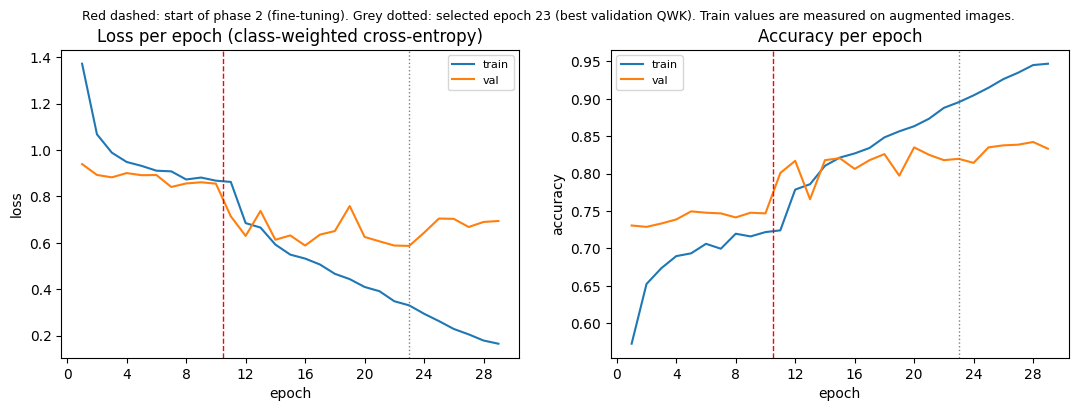

,epoch,phase,train_loss,val_loss,train_acc,val_acc,val_macro_f1,val_qwk,lr,minutes
0,1,1,1.3720,0.9394,0.5725,0.7306,0.5901,0.7898,9.76e-04,3.9192
1,2,1,1.0677,0.8926,0.6524,0.7288,0.5578,0.7900,9.05e-04,3.2249
2,3,1,0.9886,0.8822,0.6736,0.7333,0.5547,0.8106,7.94e-04,3.2307
3,4,1,0.9484,0.9007,0.6897,0.7387,0.5627,0.7985,6.55e-04,3.2188
4,5,1,0.9317,0.8915,0.6934,0.7495,0.5384,0.8104,5.00e-04,3.2213
5,6,1,0.9109,0.8923,0.7061,0.7477,0.5483,0.8079,3.45e-04,3.2197
6,7,1,0.9080,0.8407,0.6996,0.7468,0.5803,0.8151,2.06e-04,3.2076
7,8,1,0.8731,0.8559,0.7197,0.7414,0.5522,0.8116,9.55e-05,3.2161
8,9,1,0.8814,0.8610,0.7160,0.7477,0.5575,0.8142,2.45e-05,3.2071
9,10,1,0.8679,0.8550,0.7218,0.7468,0.5570,0.8161,0.00e+00,3.2010


In [13]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for split in ("train", "val"):
    axs[0].plot(hist.epoch, hist[f"{split}_loss"], label=split)
    axs[1].plot(hist.epoch, hist[f"{split}_acc"], label=split)
axs[0].set_title("Loss per epoch (class-weighted cross-entropy)"); axs[0].set_ylabel("loss")
axs[1].set_title("Accuracy per epoch"); axs[1].set_ylabel("accuracy")
for ax in axs:
    ax.axvline(best_ep, color="grey", ls=":", lw=1); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
    ax.axvline(hist.loc[hist.phase == 1, "epoch"].max() + 0.5, color="red", ls="--", lw=1)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.suptitle(f"Red dashed: start of phase 2 (fine-tuning). Grey dotted: selected epoch {best_ep} (best validation QWK). "
             "Train values are measured on augmented images.",
             fontsize=9)
savefig("11_training_curves")
display(hist.round(4).assign(lr=hist.lr.map(lambda v: f"{v:.2e}")))

## 7. Test evaluation
Accuracy, macro-F1 and QWK with bootstrap 95 % CIs, plus a check without duplicated images.

In [14]:
set_phase(2)                                                       # same variable layout as when saved
model.load_weights(str(WEIGHTS))                                   # weights of the epoch selected on validation
logits_te, y_te = predict(make_ds(te_df, False))
logits_va, y_va = predict(make_ds(va_df, False))
pred = logits_te.argmax(1)

rng = np.random.default_rng(0); boot = []
for _ in range(CFG["n_bootstrap"]):
    i = rng.integers(0, len(y_te), len(y_te)); boot.append(scores(y_te[i], pred[i]))
boot = pd.DataFrame(boot)
res = pd.DataFrame({"value": scores(y_te, pred), "95% CI low": boot.quantile(0.025), "95% CI high": boot.quantile(0.975)})
display(res.round(3)); res.to_csv(OUT_DIR / "test_metrics.csv")
dup = te_df.test_dup_of_train.values
print(f"Without the {dup.sum()} test images duplicated in train:",
      {k: round(v, 3) for k, v in scores(y_te[~dup], pred[~dup]).items()})

,value,95% CI low,95% CI high
accuracy,0.831,0.815,0.844
macro_f1,0.743,0.718,0.767
qwk,0.918,0.906,0.930


Without the 45 test images duplicated in train: {'accuracy': 0.827, 'macro_f1': 0.743, 'qwk': np.float64(0.917)}


### 7.1 Confusion matrix
Confusion matrix and per-class report.

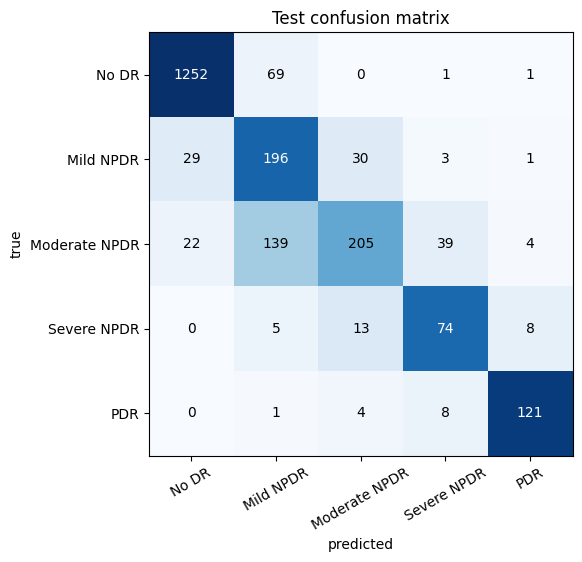

               precision    recall  f1-score   support

        No DR      0.961     0.946     0.954      1323
    Mild NPDR      0.478     0.757     0.586       259
Moderate NPDR      0.813     0.501     0.620       409
  Severe NPDR      0.592     0.740     0.658       100
          PDR      0.896     0.903     0.900       134

     accuracy                          0.831      2225
    macro avg      0.748     0.769     0.743      2225
 weighted avg      0.857     0.831     0.833      2225



In [15]:
cm = confusion_matrix(y_te, pred, labels=range(K))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
for (r, c), v in np.ndenumerate(cm):
    ax.text(c, r, v, ha="center", va="center", color="white" if v > cm.sum(1)[r] * 0.6 else "black")
ax.set_xticks(range(K), GRADES, rotation=30); ax.set_yticks(range(K), GRADES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Test confusion matrix")
savefig("12_confusion_matrix")
print(classification_report(y_te, pred, labels=range(K), target_names=GRADES, digits=3, zero_division=0))

## 8. Error analysis
Under-/over-grading, referable-DR sensitivity, performance by sharpness and worst errors.

under-graded: 9.9% | over-graded: 7.0% | off by >= 2 grades: 1.9%
referable DR (grade >= 2) sensitivity: 0.740 | specificity: 0.977 | missed PDR: 13 / 134


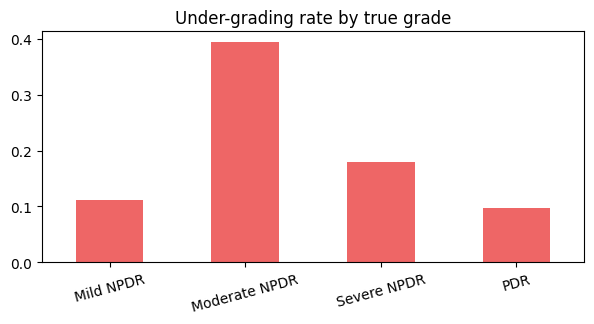

,accuracy,macro_f1,qwk
image sharpness tertile,,,
low,0.779,0.729,0.911
mid,0.819,0.740,0.884
high,0.894,0.761,0.936


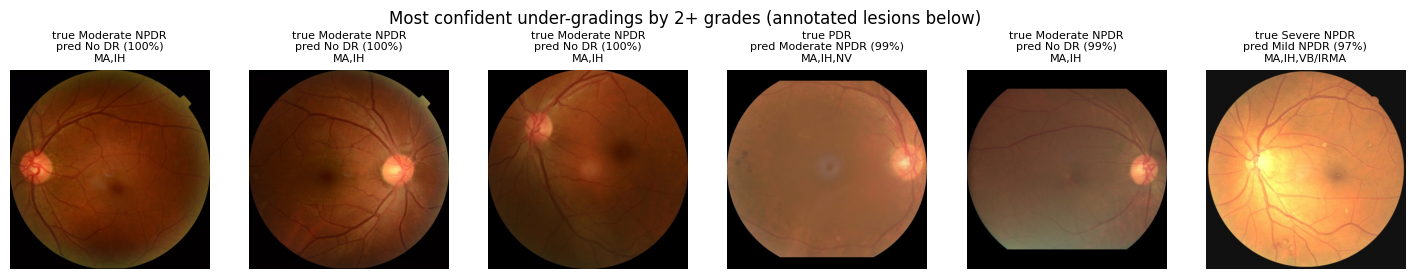

In [16]:
err = pred - y_te
print(f"under-graded: {(err < 0).mean():.1%} | over-graded: {(err > 0).mean():.1%} | off by >= 2 grades: {(abs(err) >= 2).mean():.1%}")
print(f"referable DR (grade >= 2) sensitivity: {((pred >= 2) & (y_te >= 2)).sum() / max((y_te >= 2).sum(), 1):.3f} | "
      f"specificity: {((pred < 2) & (y_te < 2)).sum() / max((y_te < 2).sum(), 1):.3f} | "
      f"missed PDR: {((y_te == 4) & (pred < 4)).sum()} / {(y_te == 4).sum()}")
pd.Series([(pred[y_te == g] < g).mean() for g in range(1, K)], index=GRADES[1:]).plot.bar(
    figsize=(7, 3), rot=15, color="#ee6666", title="Under-grading rate by true grade")
savefig("13_undergrading")
tert = pd.qcut(te_df.sharpness, 3, labels=["low", "mid", "high"]).values
display(pd.DataFrame({t: scores(y_te[tert == t], pred[tert == t]) for t in ["low", "mid", "high"]}).T.round(3)
        .rename_axis("image sharpness tertile"))
prob_te = softmax(logits_te, axis=1)
worst = np.where(err <= -2)[0]
worst = worst[np.argsort(-prob_te[worst].max(1))][:6]
if len(worst):
    fig, axs = plt.subplots(1, len(worst), figsize=(3 * len(worst), 3.3), squeeze=False)
    for ax, i in zip(axs[0], worst):
        ax.imshow(Image.open(IMG_DIR / te_df.file[i])); ax.axis("off")
        lesions = ",".join(l for l in LESIONS if te_df.loc[i, l]) or "none"
        ax.set_title(f"true {GRADES[y_te[i]]}\npred {GRADES[pred[i]]} ({prob_te[i].max():.0%})\n{lesions}", fontsize=8)
    plt.suptitle("Most confident under-gradings by 2+ grades (annotated lesions below)"); savefig("14_errors")

## 9. Reliability
Temperature scaling, 20 % referral of least-confident cases and robustness to blur/darkening.

In [17]:
def ece(prob, y, bins=10):
    conf, ok = prob.max(1), prob.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1)
    return sum(((conf > a) & (conf <= b)).mean() * abs(ok[(conf > a) & (conf <= b)].mean() - conf[(conf > a) & (conf <= b)].mean())
               for a, b in zip(edges[:-1], edges[1:]) if ((conf > a) & (conf <= b)).any())


nll = lambda logits, y: -log_softmax(logits, axis=1)[np.arange(len(y)), y].mean()
temps = np.linspace(0.5, 5, 46)
TEMP = temps[np.argmin([nll(logits_va / t, y_va) for t in temps])]
prob_cal = softmax(logits_te / TEMP, axis=1)
print(f"temperature T = {TEMP:.2f} | ECE before {ece(prob_te, y_te):.3f} -> after {ece(prob_cal, y_te):.3f}")

conf = prob_cal.max(1)
tau = np.quantile(softmax(logits_va / TEMP, axis=1).max(1), CFG["referral_rate"])
refer = conf < tau
print(f"referred for review: {refer.mean():.1%} | accuracy of referred {(pred[refer] == y_te[refer]).mean():.3f} "
      f"vs accepted {(pred[~refer] == y_te[~refer]).mean():.3f} | errors caught by referral: "
      f"{(pred[refer] != y_te[refer]).sum() / max((pred != y_te).sum(), 1):.1%}")


def gaussian_blur(img, sigma):
    """Gaussian blur of a float32 HxWx3 image (TensorFlow equivalent of PIL's GaussianBlur)."""
    k = int(2 * round(3 * sigma) + 1)
    x = tf.range(k, dtype=tf.float32) - (k - 1) / 2
    g = tf.exp(-x ** 2 / (2 * sigma ** 2)); g = g / tf.reduce_sum(g)
    kernel = tf.tile((g[:, None] * g[None, :])[:, :, None, None], [1, 1, 3, 1])
    return tf.nn.depthwise_conv2d(img[None], kernel, [1, 1, 1, 1], "SAME")[0]


rows = []
for name, fn in {"clean": None, "blur": lambda im: gaussian_blur(im, 3 * SIZE / 512),
                 "dark": lambda im: tf.clip_by_value(im * 0.6, 0.0, 255.0)}.items():
    lg, yy = predict(make_ds(te_df, False, perturb=fn))
    rows.append(dict(condition=name, **scores(yy, lg.argmax(1))))
display(pd.DataFrame(rows).set_index("condition").round(3))

temperature T = 1.40 | ECE before 0.068 -> after 0.028
referred for review: 18.9% | accuracy of referred 0.529 vs accepted 0.901 | errors caught by referral: 52.5%


,accuracy,macro_f1,qwk
condition,,,
clean,0.831,0.743,0.918
blur,0.729,0.604,0.787
dark,0.819,0.723,0.910


## 10. Explainability
Grad-CAM heatmaps for the predicted grade next to the original image.

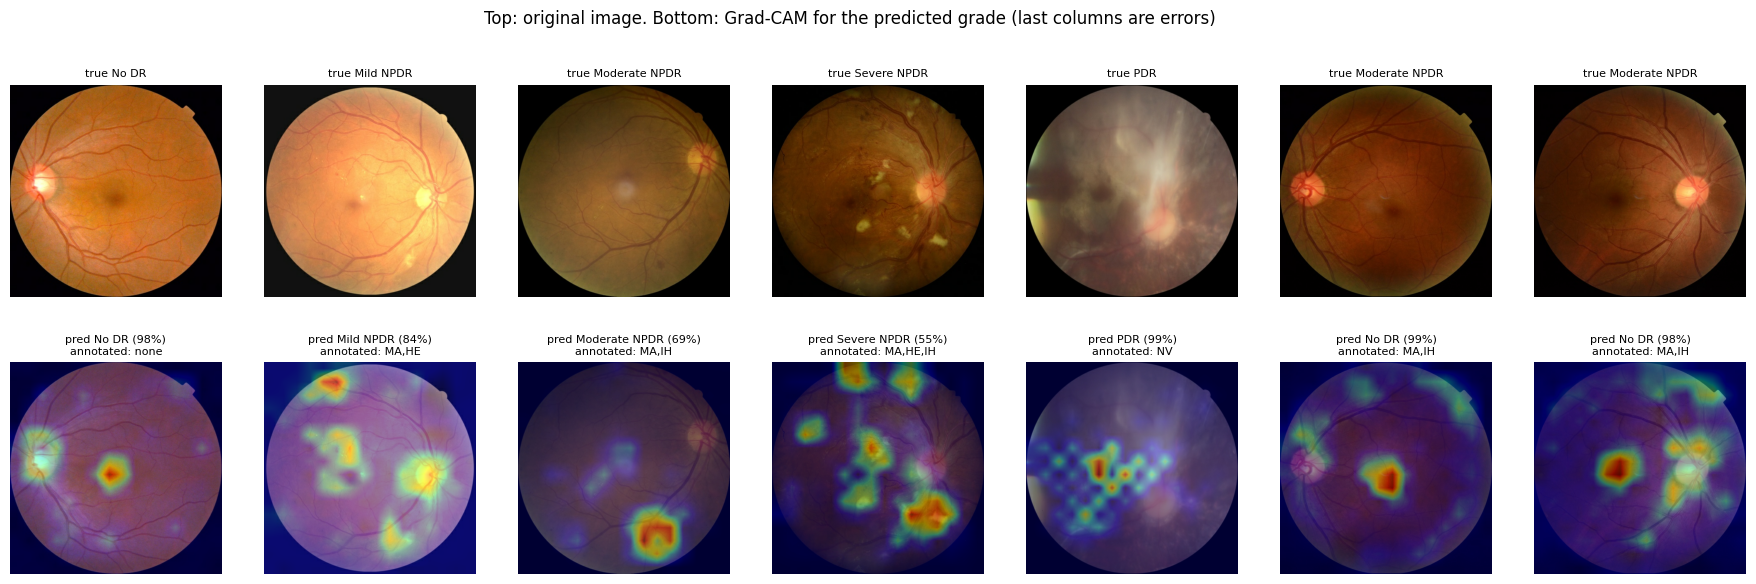

In [18]:
grad_model = keras.Model(model.input, [model.get_layer("top_activation").output, model.output])


def gradcam(x, cls):
    """Grad-CAM map in [0, 1] for class `cls` of one preprocessed image batch x (1, H, W, 3)."""
    with tf.GradientTape() as tape:
        fmap, logits = grad_model(x, training=False)
        score = logits[:, cls]
    g = tape.gradient(score, fmap)
    g, fmap = tf.cast(g, tf.float32), tf.cast(fmap, tf.float32)       # mixed precision: compute the map in float32
    cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(g, axis=(1, 2), keepdims=True) * fmap, axis=-1))[0]
    cam = tf.image.resize(cam[..., None], (SIZE, SIZE))[..., 0]
    return (cam / (tf.reduce_max(cam) + 1e-8)).numpy()


show = [te_df[(te_df.grade == g) & (pred == g)].index[0] for g in range(K) if ((te_df.grade == g) & (pred == g)).any()]
show += list(worst[:2])
fig, axs = plt.subplots(2, len(show), figsize=(3.2 * len(show), 6.6), squeeze=False)
for j, i in enumerate(show):
    img = load_image(str(IMG_DIR / te_df.file[i]))
    cam = gradcam(preprocess(img)[None], int(pred[i]))
    rgb = np.clip(img.numpy() / 255.0, 0, 1)
    axs[0, j].imshow(rgb); axs[0, j].set_title(f"true {GRADES[y_te[i]]}", fontsize=8)
    axs[1, j].imshow(rgb); axs[1, j].imshow(cam, cmap="jet", alpha=0.4)
    lesions = ",".join(l for l in LESIONS if te_df.loc[i, l]) or "none"
    axs[1, j].set_title(f"pred {GRADES[pred[i]]} ({prob_cal[i].max():.0%})\nannotated: {lesions}", fontsize=8)
    for ax in axs[:, j]: ax.axis("off")
plt.suptitle("Top: original image. Bottom: Grad-CAM for the predicted grade (last columns are errors)")
savefig("15_gradcam")

## 11. Summary
Final test metrics and output locations.

In [19]:
s = scores(y_te, pred)
print(f"BASELINE EfficientNetV2-S (two-phase, TensorFlow) | selected epoch {best_ep} / {len(hist)} (phase {best_phase}) | test accuracy {s['accuracy']:.3f}, "
      f"macro-F1 {s['macro_f1']:.3f}, QWK {s['qwk']:.3f}")
print(f"Weights: {WEIGHTS} | metrics: {OUT_DIR / 'test_metrics.csv'} | figures: {OUT_DIR / 'figures'}")

BASELINE EfficientNetV2-S (two-phase, TensorFlow) | selected epoch 23 / 29 (phase 2) | test accuracy 0.831, macro-F1 0.743, QWK 0.918
Weights: /kaggle/working/outputs_effnetv2s_baseline_tf/effnetv2s_baseline_tf_dr.weights.h5 | metrics: /kaggle/working/outputs_effnetv2s_baseline_tf/test_metrics.csv | figures: /kaggle/working/outputs_effnetv2s_baseline_tf/figures


**Limitations:** image-level split without patient IDs, some test duplicates of training images, single data source, few Severe NPDR/PDR test images. Research prototype, not a clinical tool.